# Credit Scoring — Exploratory Data Analysis

## Project Goal

Analyze credit data to identify patterns associated
with loan defaults and prepare data for machine learning.

## 1. Import Libraries

We import Pandas for data manipulation and Matplotlib
for data visualization.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load Dataset

We load the credit scoring dataset from a CSV file
using Pandas.

The dataset contains borrower characteristics,
loan information, and the target variable `default`.

In [6]:
df = pd.read_csv("../Dataset/lending_club_clean.csv")

df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,default
0,3200,36.0,7.35,99.32,0,3,10.0,5,41000.0,1,1,2.69,0.0,2.0,13.0,1.0,1989,11.8,48.0,0
1,8000,36.0,13.18,270.25,2,12,6.0,1,80000.0,1,2,9.54,0.0,1.0,4.0,0.0,4279,99.5,4.0,1
2,25000,36.0,8.90,793.84,0,4,10.0,1,150000.0,2,1,5.18,1.0,0.0,12.0,0.0,25863,67.0,27.0,0
3,6000,36.0,9.17,191.28,1,6,8.0,1,51000.0,1,9,16.24,1.0,0.0,9.0,0.0,8036,94.5,18.0,0
4,35000,36.0,14.65,1207.30,2,14,3.0,1,200000.0,2,2,29.97,0.0,1.0,13.0,0.0,22936,53.0,34.0,0


## 3. Dataset Overview

We examine the dimensions of the dataset to determine
the number of observations and features.

The `shape` attribute returns the number of rows
and columns.

In [7]:
df.shape

(150000, 20)

## 4. Data Types

In this section, we examine the structure of the dataset.

The `info()` method provides information about:
- Column names
- Data types
- Number of non-null values
- Memory usage

This helps us identify categorical and numerical features
and detect potential missing values.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            150000 non-null  int64  
 1   term                 150000 non-null  float64
 2   int_rate             150000 non-null  float64
 3   installment          150000 non-null  float64
 4   grade                150000 non-null  int64  
 5   sub_grade            150000 non-null  int64  
 6   emp_length           141357 non-null  float64
 7   home_ownership       150000 non-null  int64  
 8   annual_inc           150000 non-null  float64
 9   verification_status  150000 non-null  int64  
 10  purpose              150000 non-null  int64  
 11  dti                  149964 non-null  float64
 12  delinq_2yrs          150000 non-null  float64
 13  inq_last_6mths       150000 non-null  float64
 14  open_acc             150000 non-null  float64
 15  pub_rec              150000 

## 5. Missing Values Analysis

Missing values can affect the quality of machine learning models.

We use `isnull()` to identify missing values
and `sum()` to calculate their number in each column.

At this stage, we only investigate missing values.
No data cleaning is performed.

In [9]:
df.isnull().sum()

loan_amnt                 0
term                      0
int_rate                  0
installment               0
grade                     0
sub_grade                 0
emp_length             8643
home_ownership            0
annual_inc                0
verification_status       0
purpose                   0
dti                      36
delinq_2yrs               0
inq_last_6mths            0
open_acc                  0
pub_rec                   0
revol_bal                 0
revol_util              101
total_acc                 0
default                   0
dtype: int64

### Findings

Missing values were detected in three features:

- `emp_length`: 8,643 missing values (5.76%)
- `dti`: 36 missing values (0.024%)
- `revol_util`: 101 missing values (0.067%)

The remaining features contain no missing values.

The largest number of missing values occurs in `emp_length`.

### Conclusion

Removing all rows with missing values could lead to
unnecessary information loss.

Missing values will be handled during the preprocessing stage.

## 6. Target Variable Distribution

The target variable is `default`.

It represents whether a borrower experienced a credit default:

- `0` — No default
- `1` — Default

We calculate the number and percentage of observations
belonging to each class.

This allows us to identify potential class imbalance.

In [10]:
print(df["default"].value_counts())

print(df["default"].value_counts(normalize=True) * 100)

default
0    119727
1     30273
Name: count, dtype: int64
default
0    79.818
1    20.182
Name: proportion, dtype: float64


### Findings

The target distribution is imbalanced:

- Class 0 (No Default): 119,727 observations (79.82%)
- Class 1 (Default): 30,273 observations (20.18%)

A model that always predicts the majority class
would achieve approximately 79.82% accuracy
on this dataset.

However, such a model would fail to identify any defaults.

### Conclusion

Accuracy alone is not sufficient for model evaluation.

Additional metrics, including Precision, Recall,
F1-score, and ROC-AUC, will be considered.

## 7. Target Distribution Visualization

We visualize the target variable using a bar chart.

The chart shows the number of borrowers in each class,
making the class imbalance easier to interpret.

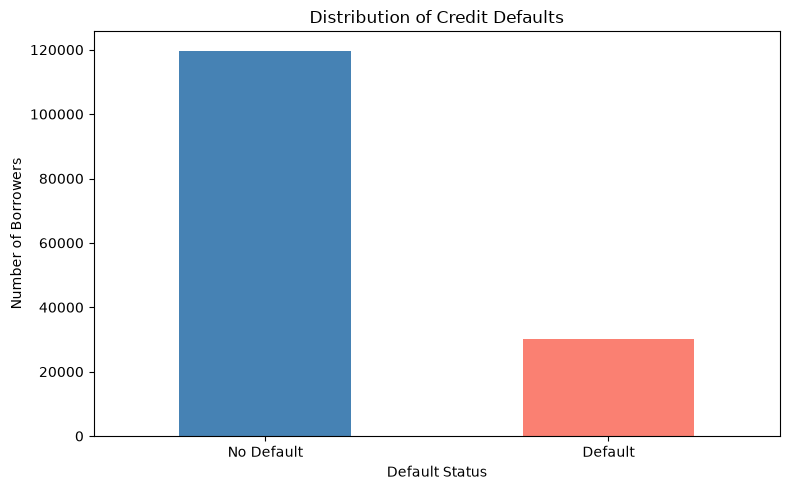

In [11]:
plt.figure(figsize=(8, 5))

df["default"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "salmon"]
)

plt.title("Distribution of Credit Defaults")
plt.xlabel("Default Status")
plt.ylabel("Number of Borrowers")

plt.xticks(
    ticks=[0, 1],
    labels=["No Default", "Default"],
    rotation=0
)

plt.tight_layout()
plt.show()

## 8. Loan Amount Descriptive Statistics

We analyze the `loan_amnt` feature to understand
the distribution of loan amounts.

The `describe()` method calculates:

- Count
- Mean
- Standard deviation
- Minimum and maximum
- Quartiles (25%, 50%, 75%)

These statistics help us understand the typical loan amount,
data variability, and potential distribution asymmetry.

In [12]:
df["loan_amnt"].describe()

count    150000.000000
mean      14410.639667
std        8692.286974
min         500.000000
25%        8000.000000
50%       12000.000000
75%       20000.000000
max       40000.000000
Name: loan_amnt, dtype: float64

### Findings

- The average loan amount is approximately 14,410.64.
- The median loan amount is 12,000.
- The middle 50% of loans range from 8,000 to 20,000.
- The minimum loan amount is 500.
- The maximum loan amount is 40,000.

The mean is higher than the median, suggesting
a potentially right-skewed distribution.

Further visualization is needed to investigate
the distribution.

## 9. Loan Amount Distribution

We use a histogram to examine the distribution of loan amounts.

A histogram divides numerical values into intervals (bins)
and shows the number of observations in each interval.

This visualization helps us:
- Identify common loan amounts.
- Examine the shape of the distribution.
- Detect potential skewness.
- Identify unusual values.

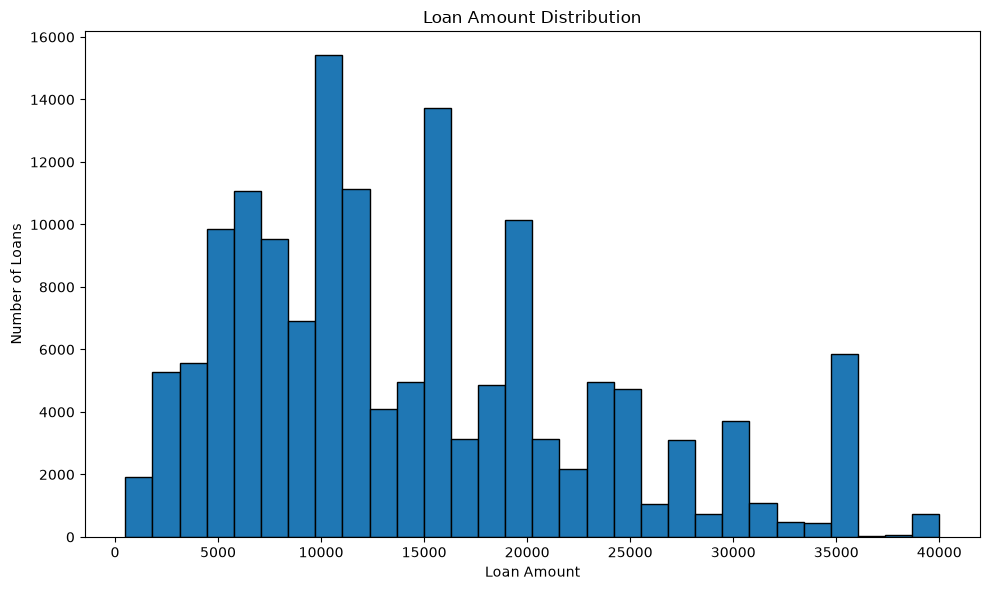

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["loan_amnt"],
    bins=30,
    edgecolor="black"
)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

### Findings

The histogram reveals several characteristics:

- A large proportion of loans are concentrated between
  approximately 5,000 and 20,000.
- The distribution is right-skewed.
- The mean loan amount (14,410.64) exceeds
  the median (12,000).
- Several peaks appear around common loan amounts.
- Larger loans are generally less frequent.

### Conclusion

The loan amount distribution shows positive skewness.

Further analysis is required to identify potential
outliers and evaluate their impact on the dataset.

## 10. Outlier Detection Using Boxplot

A boxplot visualizes the distribution of numerical data
using quartiles and the median.

We use the Interquartile Range (IQR) method
to identify potential outliers.

The IQR is calculated as:

**IQR = Q3 - Q1**

Potential outliers are values outside the following bounds:

- Lower bound: Q1 - 1.5 × IQR
- Upper bound: Q3 + 1.5 × IQR

Values outside these bounds are considered potential
outliers and require further investigation.

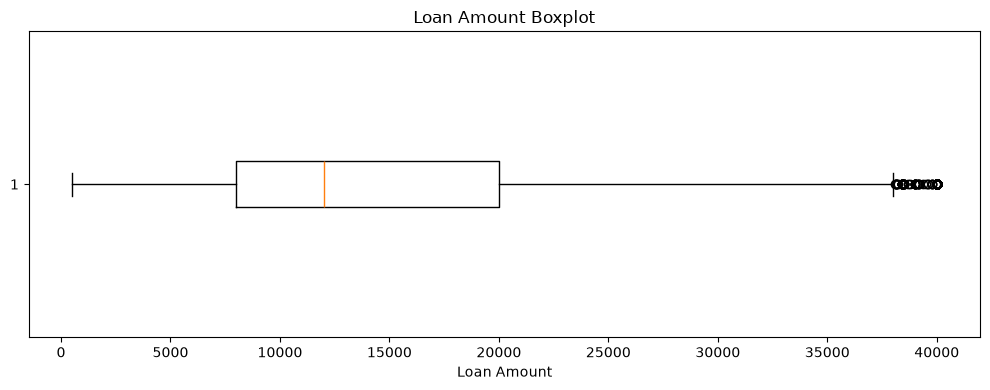

In [18]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["loan_amnt"],
    orientation="horizontal"
)

plt.title("Loan Amount Boxplot")
plt.xlabel("Loan Amount")

plt.tight_layout()
plt.show()

## 11. Outlier Quantification

After identifying potential outliers visually,
we calculate their exact number using the IQR method.

We define the lower and upper bounds and select
observations outside these limits.

At this stage, no observations are removed.

In [16]:
q1 = df["loan_amnt"].quantile(0.25)
q3 = df["loan_amnt"].quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[
    (df["loan_amnt"] < lower) |
    (df["loan_amnt"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Lower bound: -10000.0
Upper bound: 38000.0
Number of outliers: 769
Outlier percentage: 0.51 %


### Findings

The IQR analysis produced the following results:

| Statistic | Value |
|-----------|------:|
| Q1 | 8,000 |
| Q3 | 20,000 |
| IQR | 12,000 |
| Lower bound | -10,000 |
| Upper bound | 38,000 |
| Potential outliers | 769 |
| Outlier percentage | 0.51% |

### Conclusion

Only 0.51% of loan amounts fall outside the IQR bounds.

All identified potential outliers are above
the upper boundary of 38,000.

These observations may represent legitimate
large loans rather than data errors.

Therefore, no outliers are removed at this stage.

Further investigation will be performed
before deciding whether outlier treatment is necessary.

## 12. Loan Amount vs Default

In this section, we investigate the relationship between
loan amounts and credit defaults.

**Hypothesis:** Borrowers with larger loans may have
higher default rates.

We group loans by their amounts and calculate the
average value of the target variable.

Since `default` is binary (0 or 1), its mean represents
the proportion of defaults within each group.

In [19]:
df.groupby("loan_amnt")["default"].mean().head(10)

loan_amnt
500     0.000000
1000    0.125191
1025    0.000000
1050    0.200000
1075    0.000000
1100    0.153846
1125    0.166667
1150    0.250000
1175    0.000000
1200    0.113924
Name: default, dtype: float64

### Loan Amount Grouping

To obtain more reliable default rate estimates, we group
loan amounts into intervals using `pd.cut()`.

This approach reduces the impact of individual observations
and allows us to compare default rates across loan ranges.

We calculate:
- Number of loans in each group.
- Average default rate for each group.

In [21]:
loan_default_stats["default_rate_pct"] = (
    loan_default_stats["mean"] * 100
)

loan_default_stats

,count,mean,default_rate_pct
loan_amnt,,,
"(0, 10000]",61818,0.170339,17.033874
"(10000, 20000]",55652,0.218555,21.855459
"(20000, 30000]",23624,0.227946,22.794616
"(30000, 40000]",8906,0.246463,24.646306


### Default Rate by Loan Amount

We visualize the relationship between loan amount ranges
and default rates using a bar chart.

The chart helps us compare the percentage of defaults
across different loan amount groups.

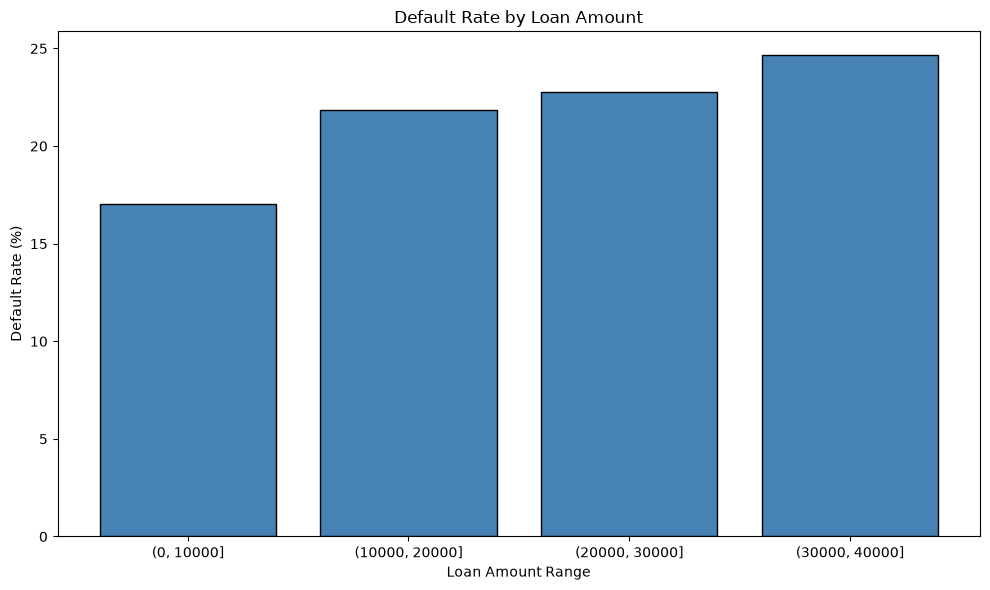

In [22]:
plt.figure(figsize=(10, 6))

plt.bar(
    loan_default_stats.index.astype(str),
    loan_default_stats["default_rate_pct"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Default Rate by Loan Amount")
plt.xlabel("Loan Amount Range")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### Findings

The analysis revealed an increasing default rate across loan amount groups.

| Loan Amount Range | Number of Loans | Default Rate |
|---|---:|---:|
| 0–10,000 | 61,818 | 17.03% |
| 10,000–20,000 | 55,652 | 21.86% |
| 20,000–30,000 | 23,624 | 22.79% |
| 30,000–40,000 | 8,906 | 24.65% |

### Key Observations

- The lowest default rate (17.03%) was observed among loans up to 10,000.
- The highest default rate (24.65%) was observed among loans between 30,000 and 40,000.
- The difference between the highest and lowest default rates is approximately 7.62 percentage points.
- Default rates increase across the analyzed loan amount ranges.

### Conclusion

The results support the hypothesis that larger loan amounts are associated with higher default rates in this dataset.

However, this relationship does not establish causation. Other borrower characteristics, such as income, credit history, and debt burden, may influence the observed pattern.

Further analysis is required to investigate these relationships.

## 13. Annual Income Analysis

Annual income (`annual_inc`) represents the borrower's
reported yearly income.

**Hypothesis:** Borrowers with lower annual incomes
may have higher default rates.

First, we examine the distribution of annual income
using descriptive statistics.

This allows us to identify:
- The average and median income.
- Minimum and maximum values.
- Income variability.
- Potential extreme values.


In [5]:
df["annual_inc"].describe()

count    1.500000e+05
mean     7.615461e+04
std      7.195752e+04
min      0.000000e+00
25%      4.600000e+04
50%      6.500000e+04
75%      9.000000e+04
max      8.706582e+06
Name: annual_inc, dtype: float64

### Annual Income Distribution

We visualize the distribution of annual income using a histogram.

The dataset contains extremely high income values, which
may distort the visualization.

To better examine the main part of the distribution,
we focus on annual incomes up to 200,000.

This filtering is applied only for visualization.
The original dataset remains unchanged.

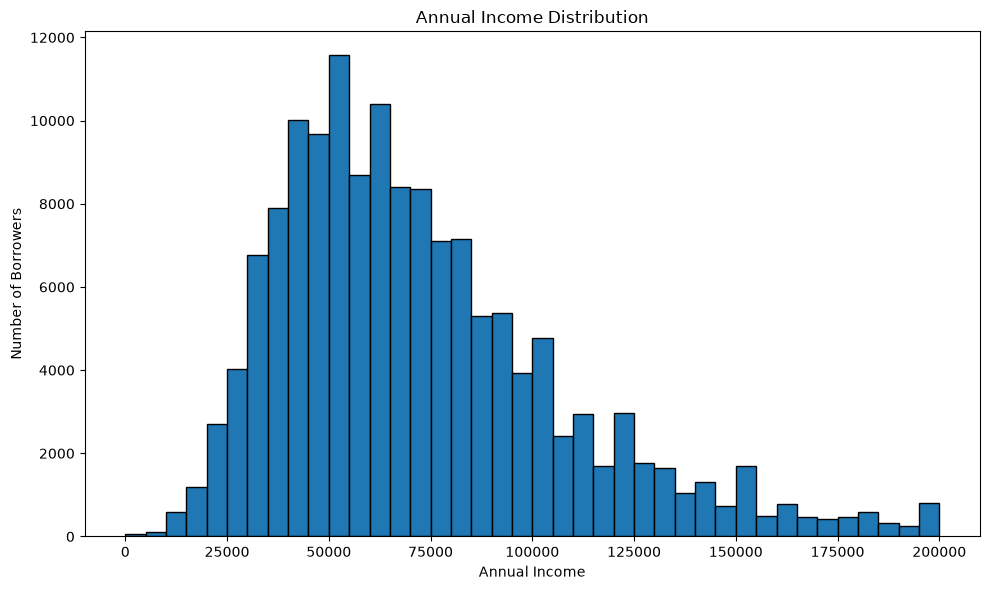

In [7]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.loc[df["annual_inc"] <= 200000, "annual_inc"],
    bins=40,
    edgecolor="black"
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Borrowers")

plt.tight_layout()
plt.show()

### Findings

The annual income distribution shows the following characteristics:

- A large proportion of borrowers have annual incomes between approximately 30,000 and 100,000.
- The highest concentration of observations is around 50,000–65,000.
- The distribution is right-skewed.
- The mean annual income (76,154.61) exceeds the median (65,000).
- Extremely high income values are present, with a maximum of approximately 8.7 million.

### Conclusion

The distribution of annual income is positively skewed, with a relatively small number of very high-income observations.

The median provides a more representative measure of typical income than the mean in this distribution.

The histogram displays only incomes up to 200,000 for visualization purposes. The original dataset remains unchanged.

## 14. Annual Income vs Default

In this section, we investigate the relationship between
annual income and credit default rates.

**Hypothesis:** Borrowers with lower annual incomes
may have higher default rates.

We divide annual income into five groups and calculate
the number of borrowers and the default rate for each group.

This analysis helps us examine whether default rates
vary across different income levels.

In [9]:
income_groups = pd.cut(
    df["annual_inc"],
    bins=[-1, 30000, 60000, 90000, 120000, float("inf")]
)

income_default_stats = df.groupby(
    income_groups,
    observed=True
)["default"].agg(["count", "mean"])

income_default_stats["default_rate_pct"] = (
    income_default_stats["mean"] * 100
)

income_default_stats

,count,mean,default_rate_pct
annual_inc,,,
"(-1.0, 30000.0]",11069,0.247177,24.717680
"(30000.0, 60000.0]",57930,0.221457,22.145693
"(60000.0, 90000.0]",44026,0.195725,19.572525
"(90000.0, 120000.0]",20491,0.169294,16.929384
"(120000.0, inf]",16484,0.159063,15.906333


### Default Rate by Annual Income

We visualize default rates across different annual income groups.

The chart allows us to compare credit default rates
and identify potential relationships between
borrowers' income levels and credit risk.

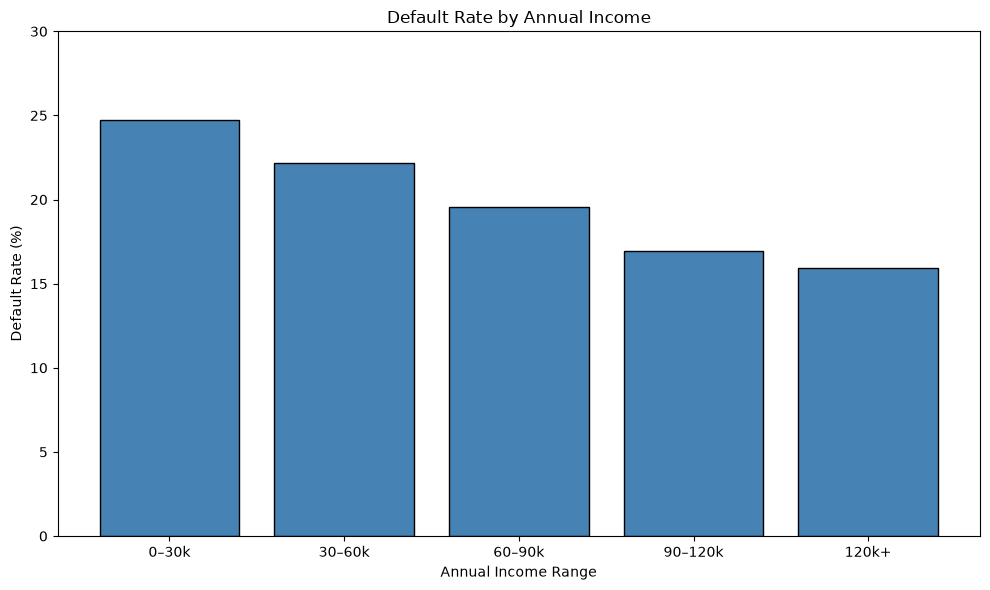

In [10]:
income_labels = [
    "0–30k",
    "30–60k",
    "60–90k",
    "90–120k",
    "120k+"
]

plt.figure(figsize=(10, 6))

plt.bar(
    income_labels,
    income_default_stats["default_rate_pct"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Default Rate by Annual Income")
plt.xlabel("Annual Income Range")
plt.ylabel("Default Rate (%)")

plt.ylim(0, 30)

plt.tight_layout()
plt.show()

### Findings

The analysis revealed a decreasing default rate as annual income increases.

| Annual Income | Number of Borrowers | Default Rate |
|---|---:|---:|
| 0–30,000 | 11,069 | 24.72% |
| 30,000–60,000 | 57,930 | 22.15% |
| 60,000–90,000 | 44,026 | 19.57% |
| 90,000–120,000 | 20,491 | 16.93% |
| Above 120,000 | 16,484 | 15.91% |

### Key Observations

- The highest default rate (24.72%) is observed in the lowest income group.
- The lowest default rate (15.91%) is observed among borrowers earning more than 120,000 annually.
- The difference between these groups is approximately 8.81 percentage points.
- Default rates decrease consistently across the analyzed income groups.

### Conclusion

The results support the hypothesis that lower annual income is associated with higher default rates.

However, the observed relationship does not establish causation. Other factors, such as debt burden, loan amount, and credit history, may influence default risk.

Further analysis is required to investigate these relationships.

## 15. Debt-to-Income Ratio Analysis

The Debt-to-Income Ratio (DTI) measures a borrower's debt
burden relative to their income.

**Hypothesis:** Borrowers with higher debt burdens may
have higher default rates.

First, we examine the distribution of `dti` using
descriptive statistics to identify its range, variability,
and potential extreme values.

In [11]:
df["dti"].describe()

count    149964.000000
mean         18.241684
std          11.089209
min           0.000000
25%          11.790000
50%          17.570000
75%          24.000000
max         999.000000
Name: dti, dtype: float64

### DTI Distribution

We visualize the distribution of the debt-to-income ratio
using a histogram.

The maximum DTI value is 999, which is significantly higher
than the median of 17.57.

To better understand the main distribution, we focus on
DTI values between 0 and 50.

This filtering is applied only for visualization.
The original dataset remains unchanged.

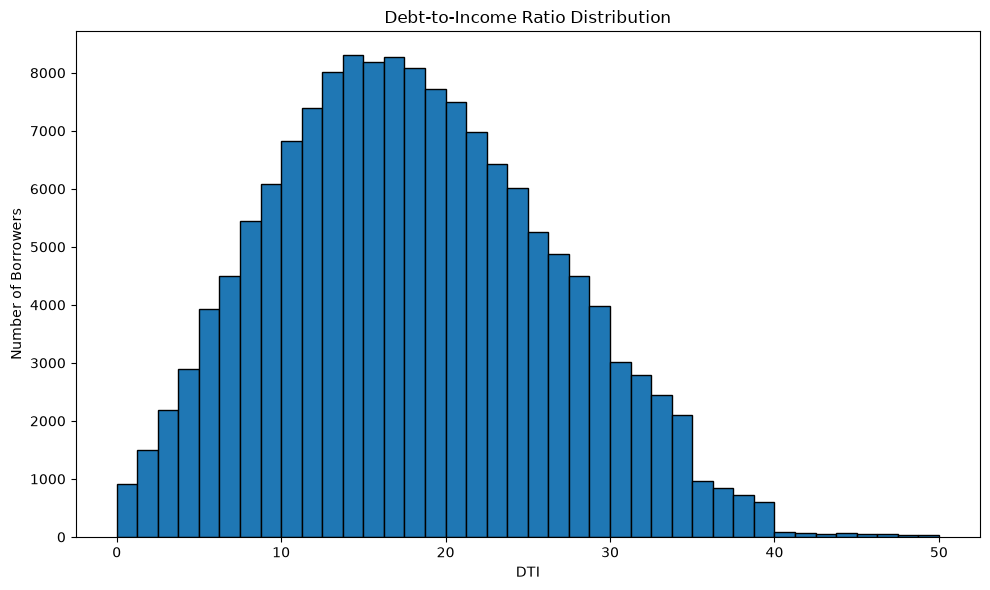

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.loc[df["dti"].between(0, 50), "dti"].dropna(),
    bins=40,
    edgecolor="black"
)

plt.title("Debt-to-Income Ratio Distribution")
plt.xlabel("DTI")
plt.ylabel("Number of Borrowers")

plt.tight_layout()
plt.show()

### Findings

The DTI distribution shows the following characteristics:

- Most borrowers have DTI values concentrated approximately between 10 and 25.
- The highest concentration of observations is around 15–17.
- The median DTI is 17.57, while the mean is approximately 18.24.
- The middle 50% of observations have DTI values between 11.79 and 24.
- The displayed distribution shows moderate right-skewness.
- The maximum recorded DTI is 999, which is unusually high compared to the median.

### Conclusion

Most borrowers have relatively moderate DTI values, while some observations contain unusually high values.

The histogram is restricted to DTI values between 0 and 50 for better visualization. The original dataset remains unchanged.

Further investigation is required to understand extreme DTI values and determine whether they represent valid observations or data quality issues.

## 16. DTI vs Default

In this section, we investigate the relationship between
debt-to-income ratio (DTI) and credit default rates.

**Hypothesis:** Borrowers with higher DTI values may
have higher default rates.

We group borrowers into different DTI ranges and
calculate the number of observations and default
rate within each group.

Missing DTI values are excluded from this analysis.
Extreme values are included in a separate group.

In [14]:
dti_groups = pd.cut(
    df["dti"],
    bins=[-1, 10, 20, 30, 40, 50, float("inf")]
)

dti_default_stats = df.groupby(
    dti_groups,
    observed=True
)["default"].agg(["count", "mean"])

dti_default_stats["default_rate_pct"] = (
    dti_default_stats["mean"] * 100
)

dti_default_stats

,count,mean,default_rate_pct
dti,,,
"(-1.0, 10.0]",27501,0.152213,15.221265
"(10.0, 20.0]",62828,0.180429,18.042911
"(20.0, 30.0]",45492,0.232217,23.221665
"(30.0, 40.0]",13458,0.293580,29.358003
"(40.0, 50.0]",424,0.377358,37.735849
"(50.0, inf]",261,0.275862,27.586207


### Default Rate by DTI

We visualize default rates across different debt-to-income
ratio groups.

The chart helps us examine how default rates change
as borrowers' debt burden increases.

The number of observations in each group should be
considered when interpreting the results.

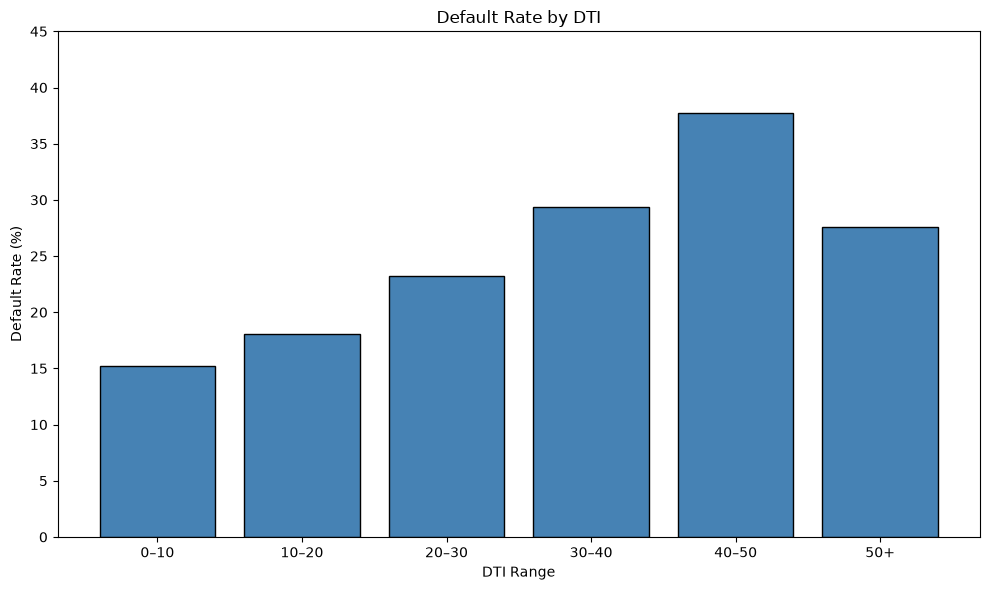

In [15]:
dti_labels = [
    "0–10",
    "10–20",
    "20–30",
    "30–40",
    "40–50",
    "50+"
]

plt.figure(figsize=(10, 6))

plt.bar(
    dti_labels,
    dti_default_stats["default_rate_pct"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Default Rate by DTI")
plt.xlabel("DTI Range")
plt.ylabel("Default Rate (%)")

plt.ylim(0, 45)

plt.tight_layout()
plt.show()

### Findings

The analysis revealed a relationship between debt-to-income ratio (DTI) and default rates.

| DTI Range | Number of Borrowers | Default Rate |
|---|---:|---:|
| 0–10 | 27,501 | 15.22% |
| 10–20 | 62,828 | 18.04% |
| 20–30 | 45,492 | 23.22% |
| 30–40 | 13,458 | 29.36% |
| 40–50 | 424 | 37.74% |
| Above 50 | 261 | 27.59% |

### Key Observations

- Default rates increase consistently across DTI groups from 0–10 to 40–50.
- The lowest default rate (15.22%) is observed in the 0–10 group.
- The highest default rate (37.74%) is observed in the 40–50 group.
- The default rate decreases to 27.59% for DTI values above 50.
- The two highest DTI groups contain relatively few observations, making their estimates less reliable.

### Conclusion

The results generally support the hypothesis that higher debt-to-income ratios are associated with higher default rates.

However, the relationship is not strictly increasing across all DTI groups.

The decline in default rates above DTI 50 should be interpreted cautiously because of the small sample size and possible extreme values.

Further investigation is required before drawing stronger conclusions about extreme DTI values.

## 17. Correlation Analysis

We calculate a correlation matrix to examine linear
relationships between numerical features and the target variable.

Pearson correlation coefficients range from -1 to 1:

- Positive values indicate positive linear relationships.
- Negative values indicate negative linear relationships.
- Values close to zero indicate weak linear relationships.

Correlation does not imply causation.

Some categorical features are encoded as integers.
Their correlations should be interpreted cautiously.

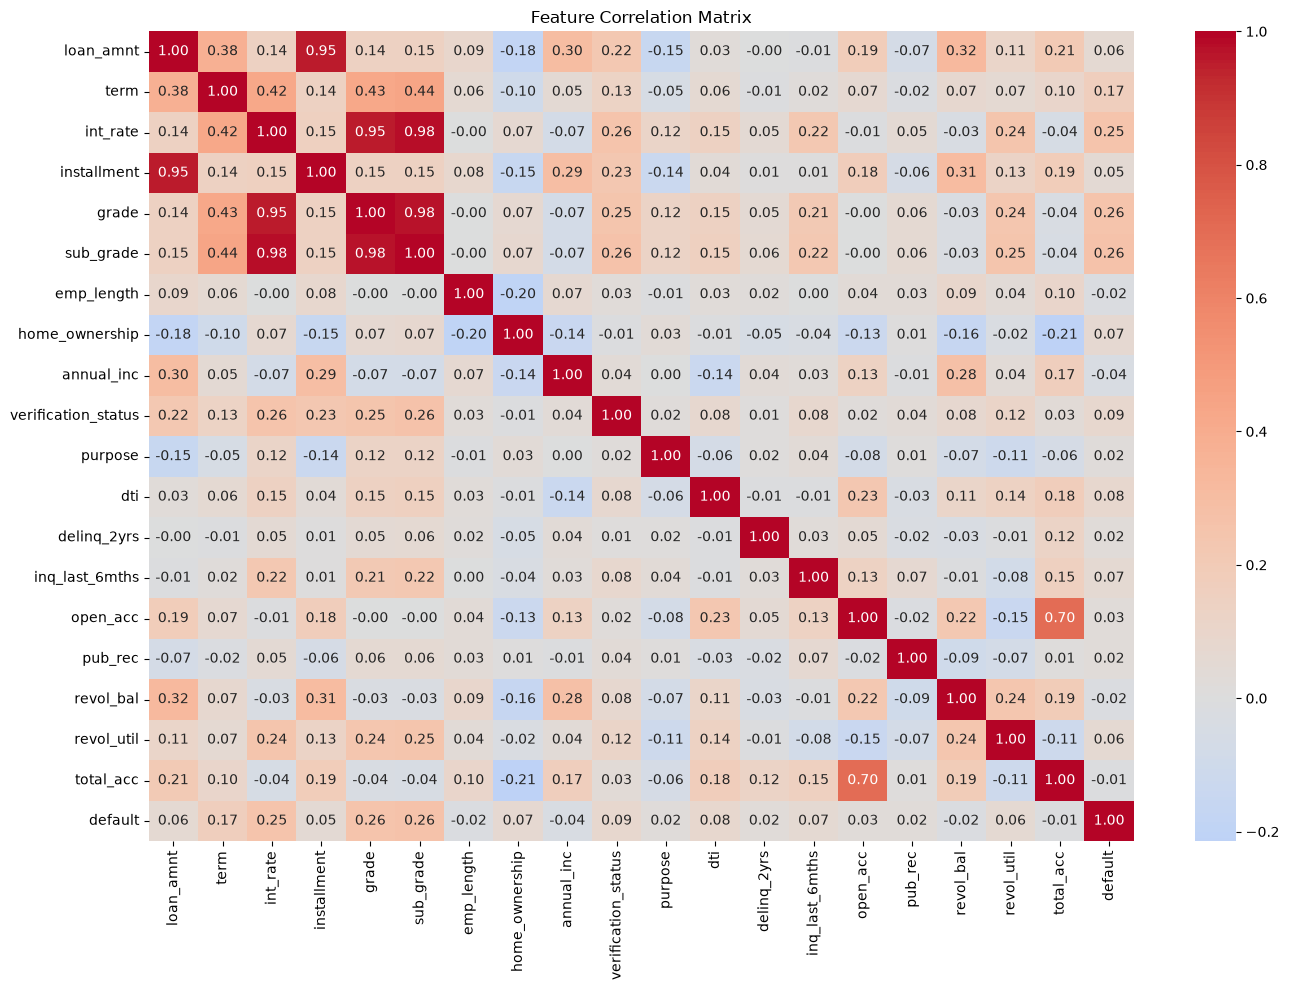

In [16]:
import seaborn as sns

corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

### Findings

The correlation matrix reveals several important relationships between features and the target variable.

**Correlation with Default:**

- `grade`: 0.26
- `sub_grade`: 0.26
- `int_rate`: 0.25
- `term`: 0.17
- `dti`: 0.08
- `loan_amnt`: 0.06
- `annual_inc`: -0.04

The strongest linear associations with default are observed for `grade`, `sub_grade`, and `int_rate`.

**Strong Feature Correlations:**

- `grade` and `sub_grade`: 0.98
- `int_rate` and `sub_grade`: 0.98
- `int_rate` and `grade`: 0.95
- `loan_amnt` and `installment`: 0.95
- `open_acc` and `total_acc`: 0.70

These relationships suggest potential multicollinearity among some features.

### Conclusion

Credit grade, sub-grade, and interest rate show the strongest linear associations with the target variable.

Several input features are highly correlated, which may affect coefficient interpretation in linear models.

Low Pearson correlation does not necessarily indicate that a feature is irrelevant for machine learning.

Additionally, some categorical features are numerically encoded, so their Pearson correlations should be interpreted cautiously.

Further feature analysis and data preprocessing are required before model training.

## 18. Categorical Features Analysis

Some categorical features in the dataset are encoded
as numerical values.

We examine their unique values to understand
their structure before preprocessing.

Categorical features include:
- `grade`
- `sub_grade`
- `home_ownership`
- `verification_status`
- `purpose`

The numerical encoding of these features must be
considered when preparing data for machine learning.

In [18]:
categorical_features = [
    "grade",
    "sub_grade",
    "home_ownership",
    "verification_status",
    "purpose"
]

for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].value_counts().sort_index())


grade:
grade
0    26231
1    43730
2    42403
3    22469
4    10534
5     3593
6     1040
Name: count, dtype: int64

sub_grade:
sub_grade
0     4887
1     4104
2     4181
3     5926
4     7133
5     7979
6     8191
7     9142
8     9223
9     9195
10    9510
11    8699
12    8414
13    8275
14    7505
15    5721
16    4973
17    4442
18    4010
19    3323
20    2645
21    2432
22    2015
23    1765
24    1677
25    1134
26     843
27     678
28     520
29     418
30     315
31     250
32     192
33     143
34     140
Name: count, dtype: int64

home_ownership:
home_ownership
0       37
1    74141
2        6
3       22
4    16074
5    59720
Name: count, dtype: int64

verification_status:
verification_status
0    45397
1    58141
2    46462
Name: count, dtype: int64

purpose:
purpose
0      1667
1     32898
2     87169
3        37
4      9762
5       839
6      3148
7      1724
8      1049
9      8538
10       99
11     1754
12     1050
13      266
Name: count, dtype: int64


### Findings

The dataset contains several numerically encoded categorical features.

| Feature | Unique Categories |
|---|---:|
| `grade` | 7 |
| `sub_grade` | 35 |
| `home_ownership` | 6 |
| `verification_status` | 3 |
| `purpose` | 14 |

### Key Observations

- `grade` and `sub_grade` represent credit risk categories with a natural ordering.
- `home_ownership`, `verification_status`, and `purpose` represent nominal categories.
- Numerical encoding does not necessarily imply a meaningful numerical relationship between categories.
- The original category mappings need to be verified before preprocessing.

### Conclusion

Different categorical features may require different encoding strategies.

One-Hot Encoding may be appropriate for nominal features, while ordinal encoding may be considered for ordered categories.

The final encoding strategy will be selected during data preprocessing.

## 19. EDA Summary

The exploratory data analysis provided several important insights into the credit scoring dataset.

### Key Findings

- The dataset contains 150,000 observations, 19 input features, and one binary target variable.
- The target variable is imbalanced, with approximately 20.18% of observations belonging to the default class.
- Missing values were identified in `emp_length`, `dti`, and `revol_util`.
- Loan amounts and annual incomes exhibit right-skewed distributions.
- Larger loan amounts are associated with higher observed default rates.
- Higher annual incomes are associated with lower observed default rates.
- Default rates generally increase with debt-to-income ratio, although extreme DTI groups require further investigation.
- Credit grade, sub-grade, and interest rate show the strongest linear associations with default among the examined features.
- Several features exhibit high correlations, indicating potential multicollinearity.
- Some categorical features are numerically encoded and require appropriate preprocessing.

### Next Steps

The next stage focuses on preparing the dataset for machine learning.

Planned activities include:

1. Investigating potential data leakage.
2. Verifying categorical feature encoding.
3. Splitting data into training and test sets.
4. Handling missing values.
5. Encoding categorical features.
6. Scaling numerical features.
7. Training a Logistic Regression baseline model.

### Conclusion

The EDA revealed several relationships between borrower characteristics and credit defaults.

These findings provide a foundation for feature preprocessing and model development.

The next objective is to build an initial classification model and evaluate its predictive performance on unseen data.